# Polynomial regression 


Polynomial Regression is a supervised machine learning algorithm used for regression problems, where we predict a continuous numerical value

# all information clink on the below link 

https://docs.google.com/document/d/1vhE6mgznBXCPv2Itltw2af1EMdDnkrtKRUiezQWM_n0/edit?usp=sharing

# Notes and interview Q and A

https://docs.google.com/document/d/18uMHa_LA04hk8mytXlrjkY4fdcelUjpcPOuFnCPewrU/edit?usp=sharing

# Code

# Import libraries

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import(mean_absolute_error, mean_squared_error, r2_score)
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


`Check the data`

In [2]:
print("Shape:", df.shape)

# result should be (20640, 9)
# That means (20640 - rows, 8 - features, & 1 target . )

Shape: (20640, 9)


`Understand the dataset `

In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


In [4]:
# Check statistics
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
# Check missing values
df.isnull().sum()

#  result is 0 because no missing values have in this dataset.

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [6]:
# Separate Features and Target
# My target is MedHouseVal

X = df.drop("MedHouseVal", axis=1) #create X 
y = df["MedHouseVal"] # create y 

In [7]:
X.shape



(20640, 8)

In [8]:
y.shape

(20640,)

In [9]:
# Train - Test Split 
# We will keep the 20% of the data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [10]:
print("X_train size", X_train.shape)
print("X_test size", X_test.size)

print("y_train size", y_train.shape)
print("y_test size", y_test.shape)

X_train size (16512, 8)
X_test size 33024
y_train size (16512,)
y_test size (4128,)


# build a baseline linear regression model 
`Before a Baseline Linear regression Model`

In [11]:
# Create a Linear Regression model.
linear_model = LinearRegression()

# Train the model using the training data.
#
# The model learns the relationship between:
# X_train → input features
# y_train → actual target values
linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.45, 0.01,-0.12,...,-0. ,-0.42,-0.43]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-37.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


`Predict`

In [12]:
# make Linear regression predictions

# Use the trained model to predict house values
# for the unseen test data.
y_pred_linear = linear_model.predict(X_test)


# Evaluate linear regression 

In [13]:
def evaluate_model(y_true, y_pred):
    # MAE = Mean Absolute Error.
    #
    # It tells us the average absolute difference
    # between actual and predicted values.
    mae = mean_absolute_error(y_true, y_pred)

    # MSE = Mean Squared Error.
    #
    # It squares the errors before averaging them.
    # Therefore, large errors are penalized more.
    mse = mean_squared_error(y_true, y_pred)

    # RMSE = Root Mean Squared Error.
    #
    # Taking the square root of MSE brings the metric
    # back to the original target's unit.
    rmse = np.sqrt(mse)

    # R² measures how much variation in the target
    # is explained by the model.
    r2 = r2_score(y_true, y_pred)

    # Print all evaluation metrics.
    print("MAE :", mae)
    print("MSE :", mse)
    print("RMSE:", rmse)
    print("R²  :", r2)

In [14]:
print("Linear Regression Performance")
print("-" * 40)

evaluate_model(y_test, y_pred_linear)

Linear Regression Performance
----------------------------------------
MAE : 0.5332001304956576
MSE : 0.5558915986952445
RMSE: 0.7455813830127765
R²  : 0.5757877060324507


# Now the important part is Polynomial features 
`This is where polynomial regression begins.`

In [15]:
# create polynomial features
# PolynomialFeatures creates additional polynomial features.
#
# degree=2 means:
# - original features
# - squared features
# - interaction features
#
# include_bias=False prevents PolynomialFeatures from adding
# an extra column of ones because LinearRegression already
# handles the intercept.
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

# Transform Training data

# fit_transform() does TWO things:
#
# 1. fit() → learns the required transformation from X_train
# 2. transform() → converts X_train into polynomial features
#
# IMPORTANT:
# We fit only on training data to avoid data leakage.
X_train_poly = poly.fit_transform(X_train)

# Transform test data

# transform() converts X_test using the SAME transformation
# learned from X_train.
#
# We DO NOT use fit_transform() here.
X_test_poly = poly.transform(X_test)


# Before polynomial transformation:
print("Original number of features:", X_train.shape[1])

# After polynomial transformation:
print("Polynomial number of features:", X_train_poly.shape[1])



Original number of features: 8
Polynomial number of features: 44


# Create Polynomial regression model

Polynomial Regression is not a completely different regression model.

We first create polynomial features and then use Linear Regression.



In [16]:
# Create the Linear Regression model.
#
# This model will learn coefficients for all the
# polynomial features we created.
poly_model = LinearRegression()

In [17]:
# Train Linear Regression using the polynomial features.
poly_model.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](44,)","[ 0., 0.,-0.,...,-0., 0., 0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-16.71
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,44
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(21)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](44,)","[1.82e+09,1.30e+07,1.03e+07,...,1.45e+00,4.39e-01,1.76e-01]"


In [18]:
# make polynomial predictions
# Predict house values using the polynomial features.
y_pred_poly = poly_model.predict(X_test_poly)

In [19]:
# evaluate polynomial regression 
# transform() converts X_test using the SAME transformation
# learned from X_train.
#
# We DO NOT use fit_transform() here.
X_test_poly = poly.transform(X_test)

In [20]:
# Now we comapre

# linear regression vs polynomial regression 

# Remember = MAE  → Lower is better = MSE  → Lower is better ,RMSE → Lower is better ,R²   → Higher is better


# Create a comparison model 
# Calculate Linear Regression metrics.
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, y_pred_linear)


# Calculate Polynomial Regression metrics.
poly_mae = mean_absolute_error(y_test, y_pred_poly)
poly_mse = mean_squared_error(y_test, y_pred_poly)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, y_pred_poly)

In [21]:
# Create the table 

# Put both models' results into a DataFrame
# so that we can compare them easily.
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression (Degree 2)"
    ],

    "MAE": [
        linear_mae,
        poly_mae
    ],

    "MSE": [
        linear_mse,
        poly_mse
    ],

    "RMSE": [
        linear_rmse,
        poly_rmse
    ],

    "R2": [
        linear_r2,
        poly_r2
    ]
})

comparison

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.533200,0.555892,0.745581,0.575788
1,Polynomial Regression (Degree 2),0.516183,0.604538,0.777521,0.538664


In [22]:
# Why do we need standard scaler



# Build the polynomial regression Pipeline

# Pipeline connects multiple ML steps together.
#
# Step 1:
# PolynomialFeatures creates x² and interaction features.
#
# Step 2:
# StandardScaler standardizes those features.
#
# Step 3:
# LinearRegression learns the relationship.
#
# This is cleaner and safer than manually performing every step.
poly_pipeline = Pipeline([("polynomial_features",PolynomialFeatures(degree=2,include_bias=False)),("scaler",StandardScaler()),("linear_regression",LinearRegression())])



# Train the Pipeline 

# The pipeline performs:
#
# X_train
#   ↓
# Polynomial Features
#   ↓
# StandardScaler
#   ↓
# Linear Regression
#
# Everything is fitted using training data.
poly_pipeline.fit(X_train, y_train)

# Predict using pipeline 

# The pipeline automatically performs:
#
# X_test
#   ↓
# Polynomial transformation
#   ↓
# Scaling
#   ↓
# Prediction
#
# We don't need to manually transform X_test.
y_pred_pipeline = poly_pipeline.predict(X_test)

In [23]:
# Evaluate pipeline 
# Evaluate the final degree-2 pipeline.
print("Polynomial Regression Pipeline")
print("-" * 40)

evaluate_model(y_test, y_pred_pipeline)

Polynomial Regression Pipeline
----------------------------------------
MAE : 0.46700093346965665
MSE : 0.4643015238300944
RMSE: 0.6813967448044453
R²  : 0.6456819729262117


In [24]:
# Compare diferent degress 

# We will store the results of each polynomial degree here.
results = []


# Try polynomial degrees from 1 to 4.
for degree in [1, 2, 3, 4]:

    # Create a pipeline for the current degree.
    model = Pipeline([
        
        # Create polynomial features.
        (
            "polynomial_features",
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ),
        
        # Standardize the polynomial features.
        (
            "scaler",
            StandardScaler()
        ),
        
        # Train Linear Regression.
        (
            "linear_regression",
            LinearRegression()
        )
    ])

    # Train the pipeline.
    model.fit(X_train, y_train)

    # Predict on training data.
    train_pred = model.predict(X_train)

    # Predict on test data.
    test_pred = model.predict(X_test)

    # Calculate training R².
    train_r2 = r2_score(y_train, train_pred)

    # Calculate testing R².
    test_r2 = r2_score(y_test, test_pred)

    # Calculate test MAE.
    test_mae = mean_absolute_error(y_test, test_pred)

    # Calculate test RMSE.
    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_pred)
    )

    # Store the results.
    results.append({
        "Degree": degree,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "Test MAE": test_mae,
        "Test RMSE": test_rmse
    })

In [25]:
# Convert result into data frame


# Convert our list of results into a DataFrame.
results_df = pd.DataFrame(results)

# Display the comparison.
results_df


# remeber 
# Good situation when - Train R² → 0.70 , Test R²  → 0.68 - this is the small gap 
# Potential overfitting  -  Train R² → 0.98 , Test R²  → 0.60 , huge gap , The model is performing extremely well on training data but much worse on unseen data.

,Degree,Train R2,Test R2,Test MAE,Test RMSE
0,1,0.612551,0.575788,0.533200,0.745581
1,2,0.685268,0.645682,0.467001,0.681397
2,3,0.743587,-17.929034,0.531473,4.980439
3,4,0.764704,-905.162805,1.063604,34.459308


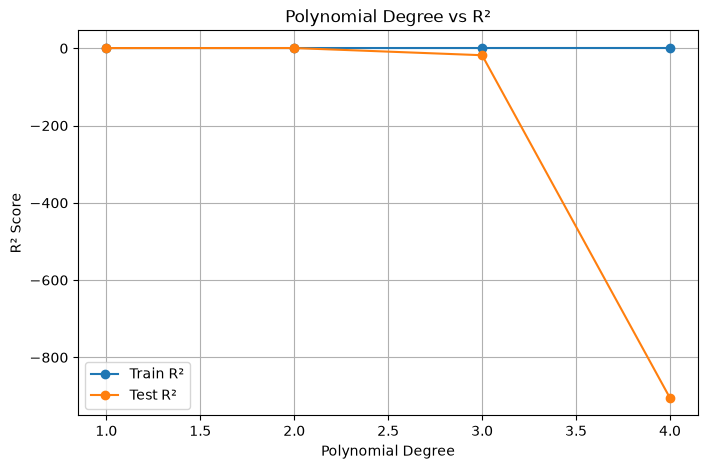

In [26]:
# Plot train vs Test r2 
# Create a graph showing how R² changes with polynomial degree.
plt.figure(figsize=(8, 5))

# Plot training R².
plt.plot(
    results_df["Degree"],
    results_df["Train R2"],
    marker="o",
    label="Train R²"
)

# Plot testing R².
plt.plot(
    results_df["Degree"],
    results_df["Test R2"],
    marker="o",
    label="Test R²"
)

# Label the x-axis.
plt.xlabel("Polynomial Degree")

# Label the y-axis.
plt.ylabel("R² Score")

# Add a title.
plt.title("Polynomial Degree vs R²")

# Display the legend.
plt.legend()

# Add grid lines.
plt.grid()

# Display the graph.
plt.show()

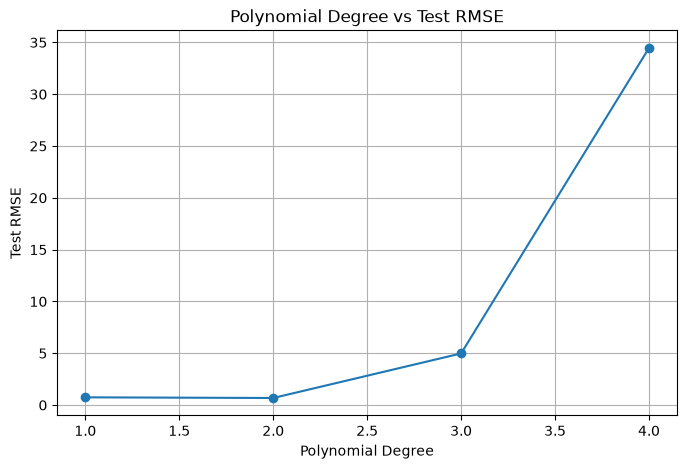

In [27]:
# Plot test in RMSE
# Plot how Test RMSE changes as polynomial degree increases.
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Degree"],
    results_df["Test RMSE"],
    marker="o"
)

# Label the x-axis.
plt.xlabel("Polynomial Degree")

# Label the y-axis.
plt.ylabel("Test RMSE")

# Add title.
plt.title("Polynomial Degree vs Test RMSE")

# Add grid.
plt.grid()

# Display graph.
plt.show()


# Remember - RMSE ↓ = Better

In [28]:
# Cross validation 

#Instead of relying on only one train/test split to select the degree, we can use cross-validation. 

# cross_val_score performs cross-validation.
from sklearn.model_selection import cross_val_score

# Store cross-validation results.
cv_results = []


# Test different polynomial degrees.
for degree in [1, 2, 3, 4]:

    # Create the complete pipeline.
    model = Pipeline([
        
        # Create polynomial features.
        (
            "polynomial_features",
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ),
        
        # Standardize features.
        (
            "scaler",
            StandardScaler()
        ),
        
        # Linear Regression model.
        (
            "linear_regression",
            LinearRegression()
        )
    ])

    # Perform 5-fold cross-validation.
    #
    # The training data is divided into 5 parts.
    # The model trains on 4 parts and validates on 1 part.
    # This repeats 5 times.
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    # Store the average R² and standard deviation.
    cv_results.append({
        "Degree": degree,
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

    # Display 

    # Convert the cross-validation results into a DataFrame.
cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Degree,Mean CV R2,Std CV R2
0,1,6.114840e-01,6.466941e-03
1,2,-6.760736e+00,1.381184e+01
2,3,-1.846107e+05,3.681890e+05
3,4,-1.198728e+07,2.392401e+07


In [29]:
# Select the best Degree

# idxmax() finds the row where Mean CV R² is highest.
best_index = cv_results_df["Mean CV R2"].idxmax()

# Get the polynomial degree from that row.
best_degree = cv_results_df.loc[
    best_index,
    "Degree"
]

print("Best Polynomial Degree:", best_degree)

Best Polynomial Degree: 1


In [33]:
# Create the final Polynomial Regression pipeline.
final_model = Pipeline([
    
    # Create polynomial features using the selected degree.
    (
        "polynomial_features",
        PolynomialFeatures(
            degree=int(best_degree),
            include_bias=False
        )
    ),
    
    # Standardize the generated features.
    (
        "scaler",
        StandardScaler()
    ),
    
    # Train Linear Regression.
    (
        "linear_regression",
        LinearRegression()
    )
])

In [34]:
# Train Final Model 

# Train the final pipeline using the training data.
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomial_features', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",1
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [35]:
# Final Prediction 

# Make predictions on completely unseen test data.
final_pred = final_model.predict(X_test)

In [36]:
# Final Evaluation 
# Evaluate the final Polynomial Regression model.
print("FINAL POLYNOMIAL REGRESSION MODEL")
print("=" * 45)

evaluate_model(y_test, final_pred)


FINAL POLYNOMIAL REGRESSION MODEL
MAE : 0.5332001304956565
MSE : 0.5558915986952442
RMSE: 0.7455813830127763
R²  : 0.575787706032451


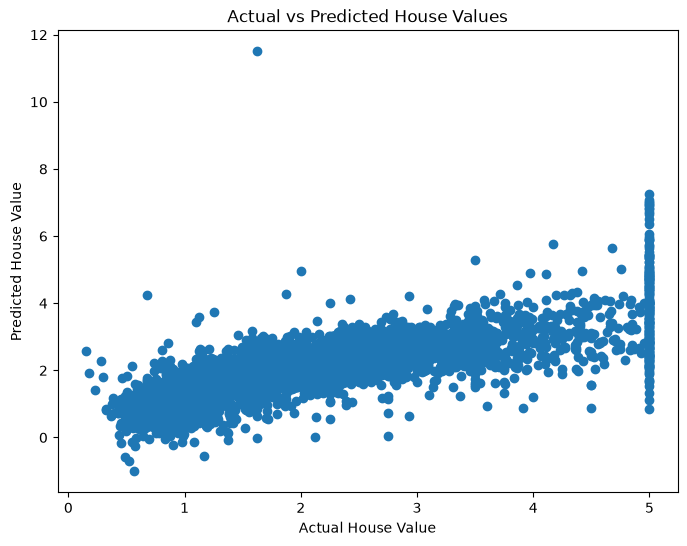

In [37]:
# Actual vs Predict Graph 

# Create an Actual vs Predicted plot.
plt.figure(figsize=(8, 6))

# Plot actual values against predicted values.
plt.scatter(
    y_test,
    final_pred
)

# Label x-axis.
plt.xlabel("Actual House Value")

# Label y-axis.
plt.ylabel("Predicted House Value")

# Add title.
plt.title("Actual vs Predicted House Values")

# Display graph.
plt.show()

In [38]:
# Residual Analysis 

# Calculate prediction errors.
residuals = y_test - final_pred

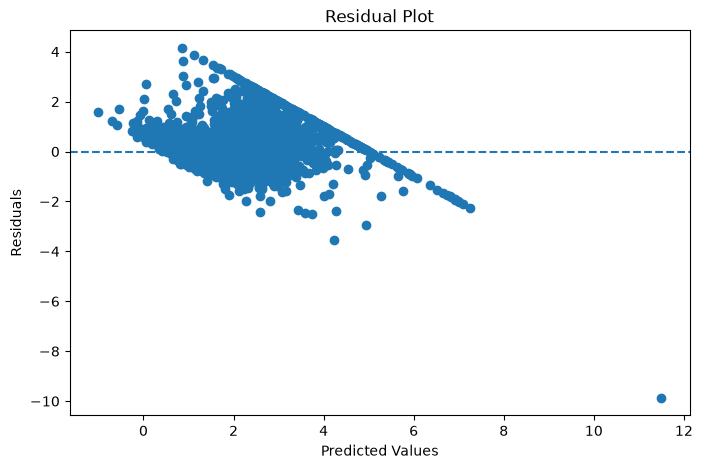

In [39]:
# Plot residuals against predicted values.
plt.figure(figsize=(8, 5))

plt.scatter(
    final_pred,
    residuals
)

# Draw a horizontal line at zero.
# Ideally, residuals should be distributed around zero.
plt.axhline(
    y=0,
    linestyle="--"
)

# Label x-axis.
plt.xlabel("Predicted Values")

# Label y-axis.
plt.ylabel("Residuals")

# Add title.
plt.title("Residual Plot")

# Display graph.
plt.show()

In [40]:
# Save the model 

# joblib is commonly used to save Scikit-learn models.
import joblib

# Save the COMPLETE pipeline.
#
# This is important because the pipeline contains:
# PolynomialFeatures
# StandardScaler
# LinearRegression
#
# Therefore, when we load it later, we don't have to
# manually repeat those preprocessing steps.
joblib.dump(
    final_model,
    "polynomial_regression_model.pkl"
)

['polynomial_regression_model.pkl']

In [41]:
# Load the saved model from disk.
loaded_model = joblib.load(
    "polynomial_regression_model.pkl"
)

In [42]:
# Test it:

# Use the loaded model to make predictions.
loaded_predictions = loaded_model.predict(X_test)

# Calculate R² to verify that the loaded model works.
loaded_r2 = r2_score(
    y_test,
    loaded_predictions
)

print("Loaded Model R²:", loaded_r2)

Loaded Model R²: 0.575787706032451
